# In Class 9

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
import xgboost as xgb
import shap

In [3]:
abalone = pd.read_csv(
    "https://raw.githubusercontent.com/dblaskey/ML_Course_Code/main/Data/abalone.csv",
    header=None,
    names=["sex", "length", "diameter", "height", "whole_weight", "shucked_weight", "viscera_weight", "shell_weight", "rings"]
)

# One-hot encode 'Sex' and separate features
X = pd.get_dummies(abalone.drop("rings", axis=1), columns=["sex"], drop_first=True)
y = abalone["rings"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [4]:
model = xgb.XGBRegressor()
model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


# Shap

`explainer = shap.Explainer(model)`: Creates a SHAP explainer for the trained model.  
`shap_values = explainer(X_test)`: Computes SHAP values for the test data to explain predictions.  
`shap.initjs()`: Initializes JavaScript support for SHAP visualizations in notebooks.  

In [10]:
explainer = shap.Explainer(model)
shap_values = explainer(X_test)
shap.initjs()

4.1 Waterfall Model

Shows how each feature contributes to the difference between the model's base value and the output prediction for a specific instance.

Color Guide:

    Red = pushes prediction higher
    Blue = pushes prediction lower

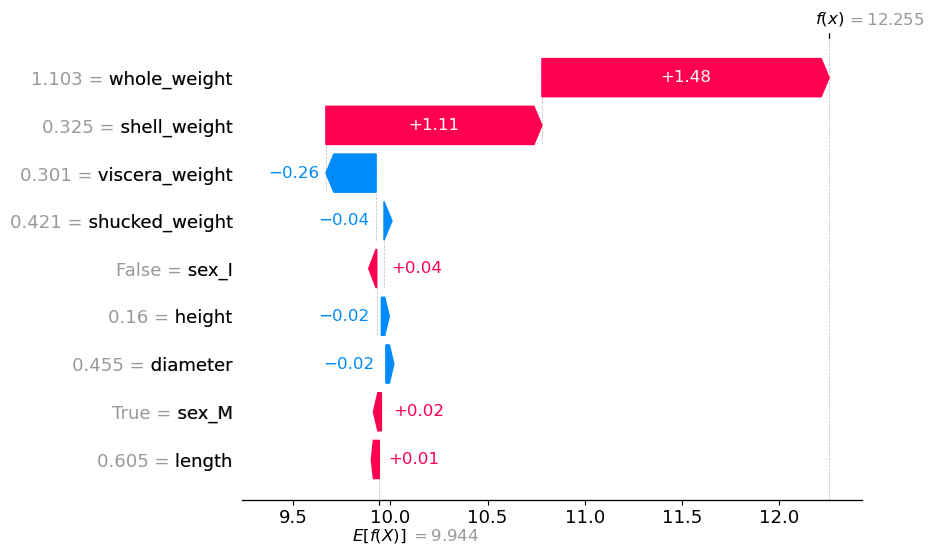

In [11]:
shap.waterfall_plot(shap_values[0])

4.2 Force Plot

Gives an interactive view of individual prediction explanations.

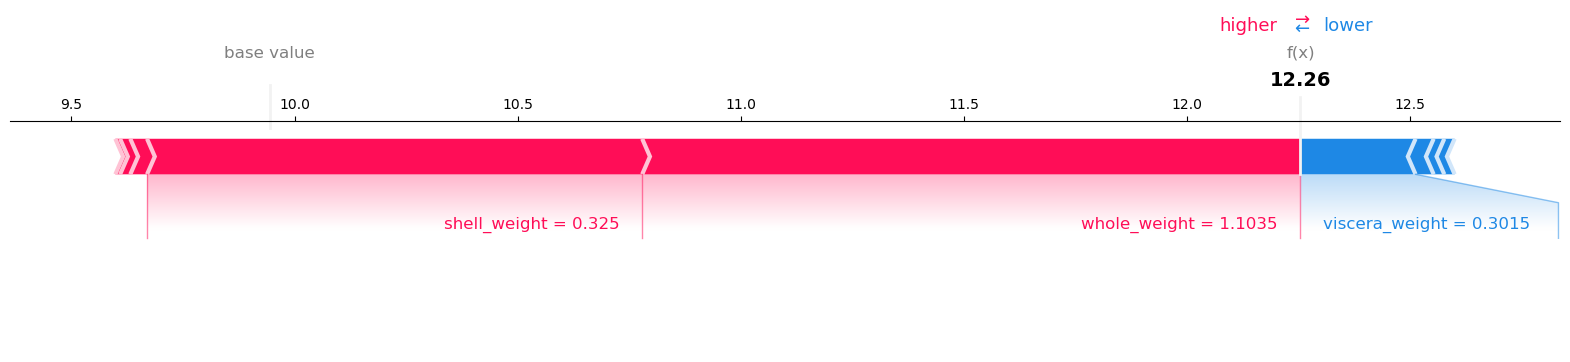

In [14]:
shap.force_plot(explainer.expected_value, shap_values[0].values, X_test.iloc[0, :], matplotlib=True)

4.3 Stacked Force Plot

Visualizes feature contributions across multiple observations.

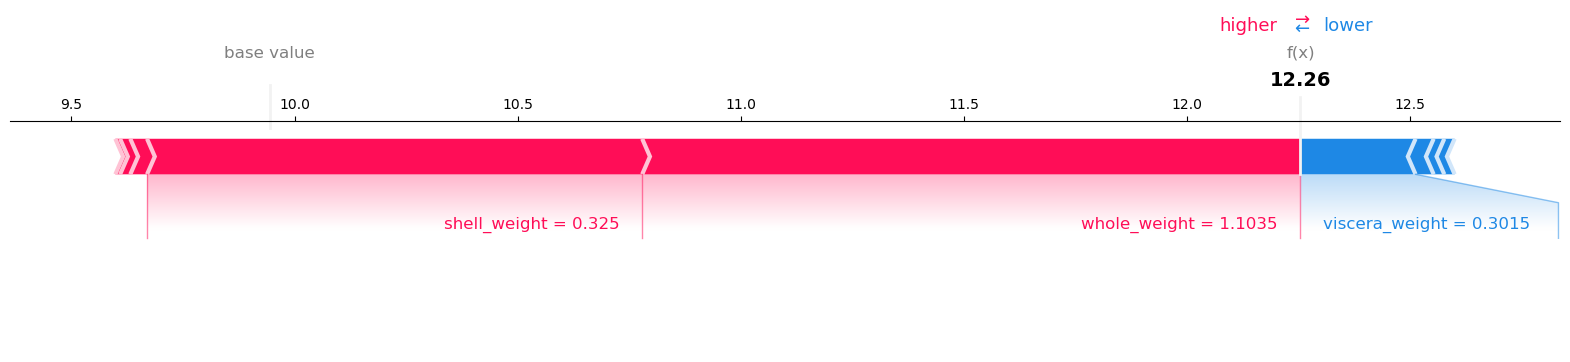

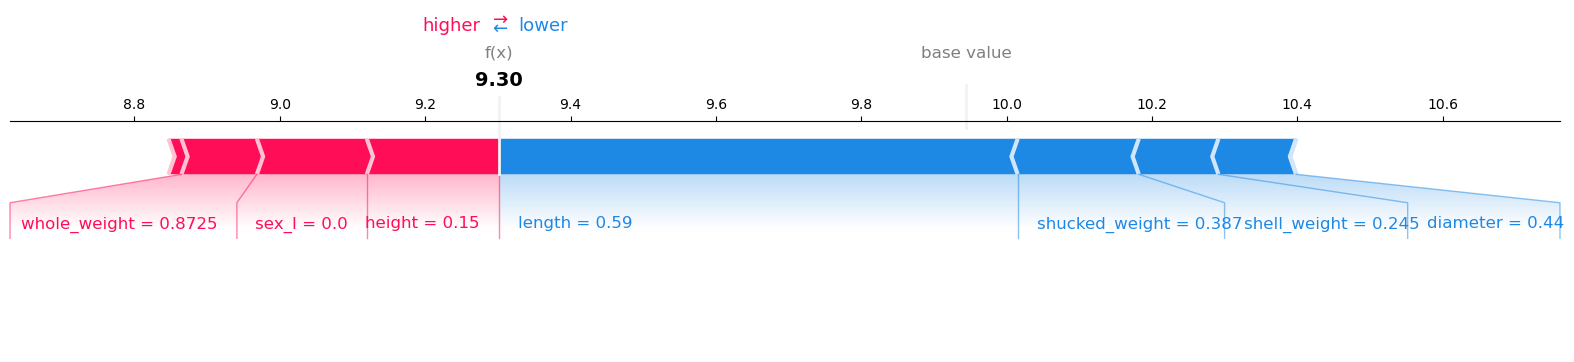

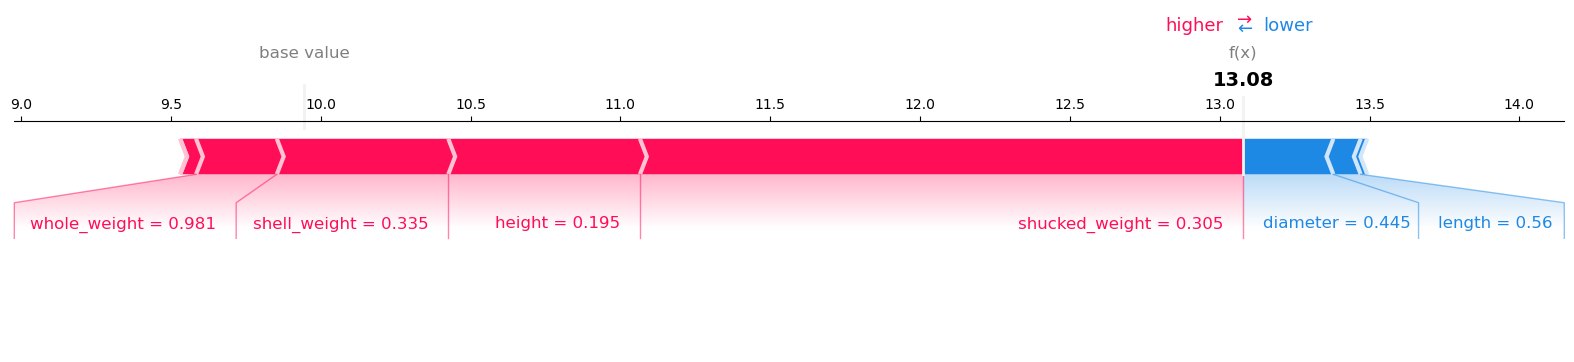

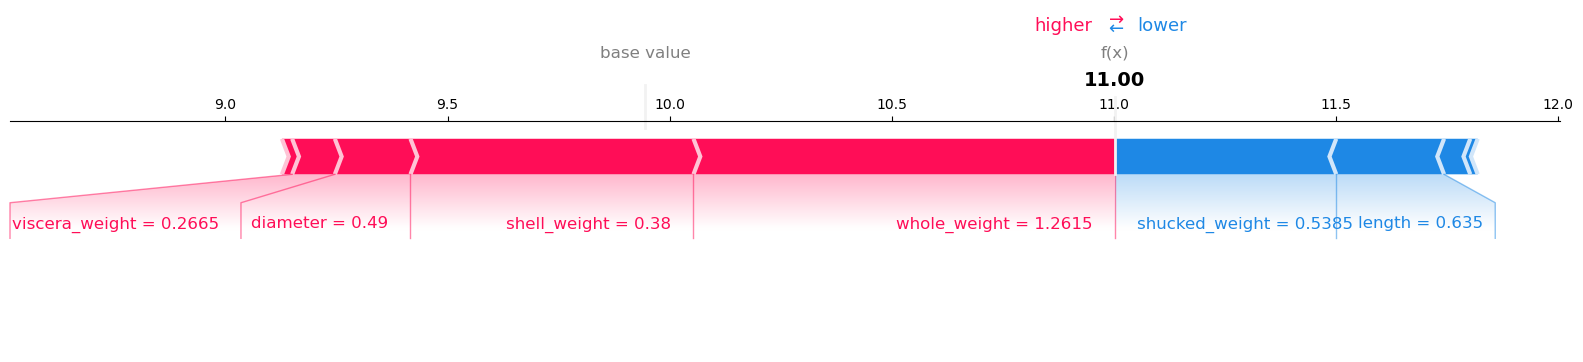

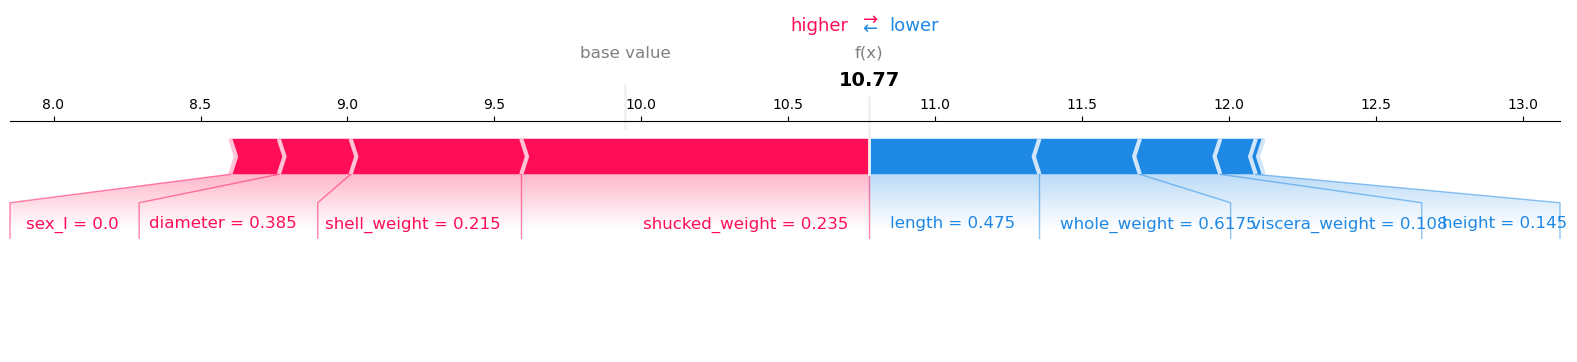

In [16]:
for i in range(5):
    shap.force_plot(explainer.expected_value, shap_values[i].values, X_test.iloc[i, :], matplotlib=True)

4.4 Summary Plot

Gives a global view of feature importance and how values influence predictions.

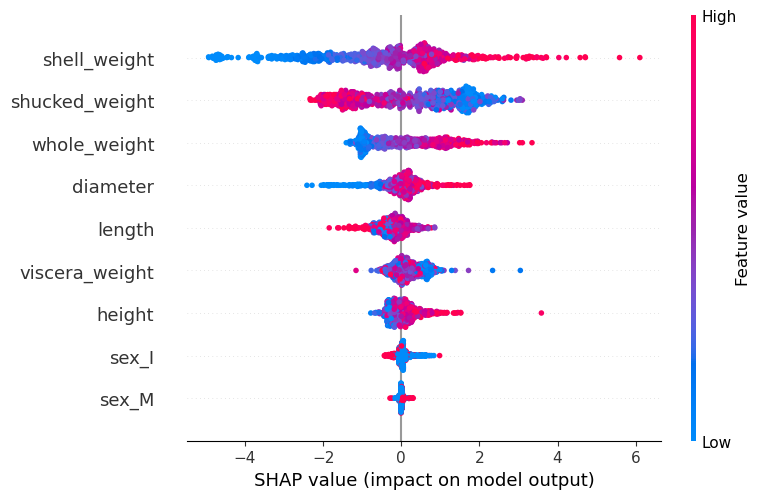

In [17]:
shap.summary_plot(shap_values, X_test)

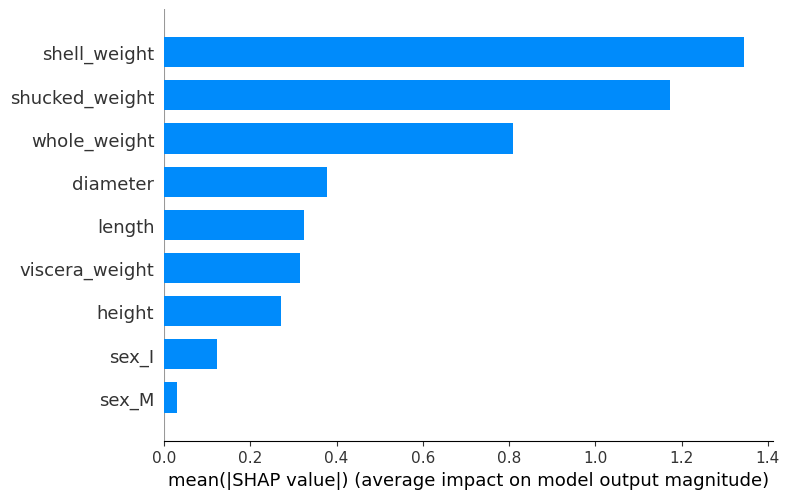

In [18]:
shap.summary_plot(shap_values, X_test, plot_type="bar")

Compare this to other feature importance metrics!